# SaaS Revenue Retention & Churn Intelligence
By Satya Ranjan Nayak. Synthetic Analytics Engineering data v1.0.0, 2023–2025. Monetary units: CU.

Rebuild source-verified metrics, inspect cohorts and investigate prospective payment-friction signals. No causal claims or fabricated NRR.

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(root)
sys.path.insert(0, str(root / 'src'))
import pandas as pd
from IPython.display import display, Image
from run_analysis import run
summary = run()

{
  "as_of": "2025-12-31",
  "accounts": 5000,
  "active_customers": 4035,
  "cancelled": 965,
  "mrr": 1387441.0,
  "arr": 16649292.0,
  "dec_logo_churn": 0.01078695758764403,
  "dec_gross_revenue_churn": 0.009702826838729939,
  "dec_churned_mrr": 13594.0,
  "arpa": 343.8515489467162,
  "risk_mrr": 396533.0,
  "risk_accounts": 1165,
  "failed_payment_rate": 0.08232611958252661,
  "open_invoice_value": 1857721.0,
  "collected_value": 27639401.0,
  "collection_rate": 0.9370202625191705,
  "total_invoiced": 29506774.0,
  "churned_mrr_all": 342673.0,
  "avg_churn_tenure_days": 352.6704663212435,
  "plan_active_mrr": {
    "Enterprise": 558069.0,
    "Growth": 272071.0,
    "Scale": 458912.0,
    "Starter": 98389.0
  },
  "landmark_sept": [
    {
      "risk_group": "0 failures",
      "accounts": 3594,
      "churned": 125,
      "churn_90d": 0.03478018920422927
    },
    {
      "risk_group": "1 failure",
      "accounts": 338,
      "churned": 11,
      "churn_90d": 0.03254437869822485

## Source integrity
NA is preserved as a region. Missing end dates encode censoring. Final-month billing anomalies are interpretation issues, not invented losses.

In [2]:
display(pd.read_csv('data/processed/quality_checks.csv'))
display(pd.read_csv('data/processed/monthly_saas_metrics.csv').tail(6))

,check,passed,detail
0,accounts primary key,True,5000
1,accounts duplicate rows,True,0
2,accounts required fields,True,"{'account_id': 0, 'created_at': 0, 'region': 0..."
3,plans primary key,True,4
4,plans duplicate rows,True,0
5,plans required fields,True,"{'plan_id': 0, 'plan_name': 0, 'monthly_price'..."
6,subscriptions primary key,True,5000
7,subscriptions duplicate rows,True,0
8,subscriptions required fields,True,"{'subscription_id': 0, 'account_id': 0, 'plan_..."
9,invoices primary key,True,85448


,month_start,beginning_customers,active_customers,new_customers,churned_customers,beginning_mrr,active_mrr,new_mrr,churned_mrr,bop_churned_customers,bop_churned_mrr,churned_tenure_days,mrr_at_risk,risk_accounts,logo_churn_rate,gross_revenue_churn,arpa,customer_retention_rate,gross_revenue_retention,arr
30,2025-07-01,3732,3852,160,40,1264234.0,1304972.0,52216.0,11478.0,40,11478.0,15449.0,314136.0,944,0.010718,0.009079,338.777778,0.989282,0.990921,15659664.0
31,2025-08-01,3852,3966,150,36,1304972.0,1361150.0,65380.0,9202.0,36,9202.0,15583.0,329684.0,1000,0.009346,0.007051,343.204740,0.990654,0.992949,16333800.0
32,2025-09-01,3966,4103,171,34,1361150.0,1416241.0,63711.0,8620.0,34,8620.0,14234.0,366576.0,1068,0.008573,0.006333,345.172069,0.991427,0.993667,16994892.0
33,2025-10-01,4103,4131,72,44,1416241.0,1417797.0,18756.0,17200.0,44,17200.0,17870.0,373759.0,1103,0.010724,0.012145,343.209150,0.989276,0.987855,17013564.0
34,2025-11-01,4131,4079,0,52,1417797.0,1401035.0,0.0,16762.0,52,16762.0,20878.0,374905.0,1119,0.012588,0.011823,343.475116,0.987412,0.988177,16812420.0
35,2025-12-01,4079,4035,0,44,1401035.0,1387441.0,0.0,13594.0,44,13594.0,17702.0,396533.0,1165,0.010787,0.009703,343.851549,0.989213,0.990297,16649292.0


## Revenue and customer movement
Balances use the latest snapshot. Flow rates use beginning exposure. SQL is executed independently from raw lifecycle dates.

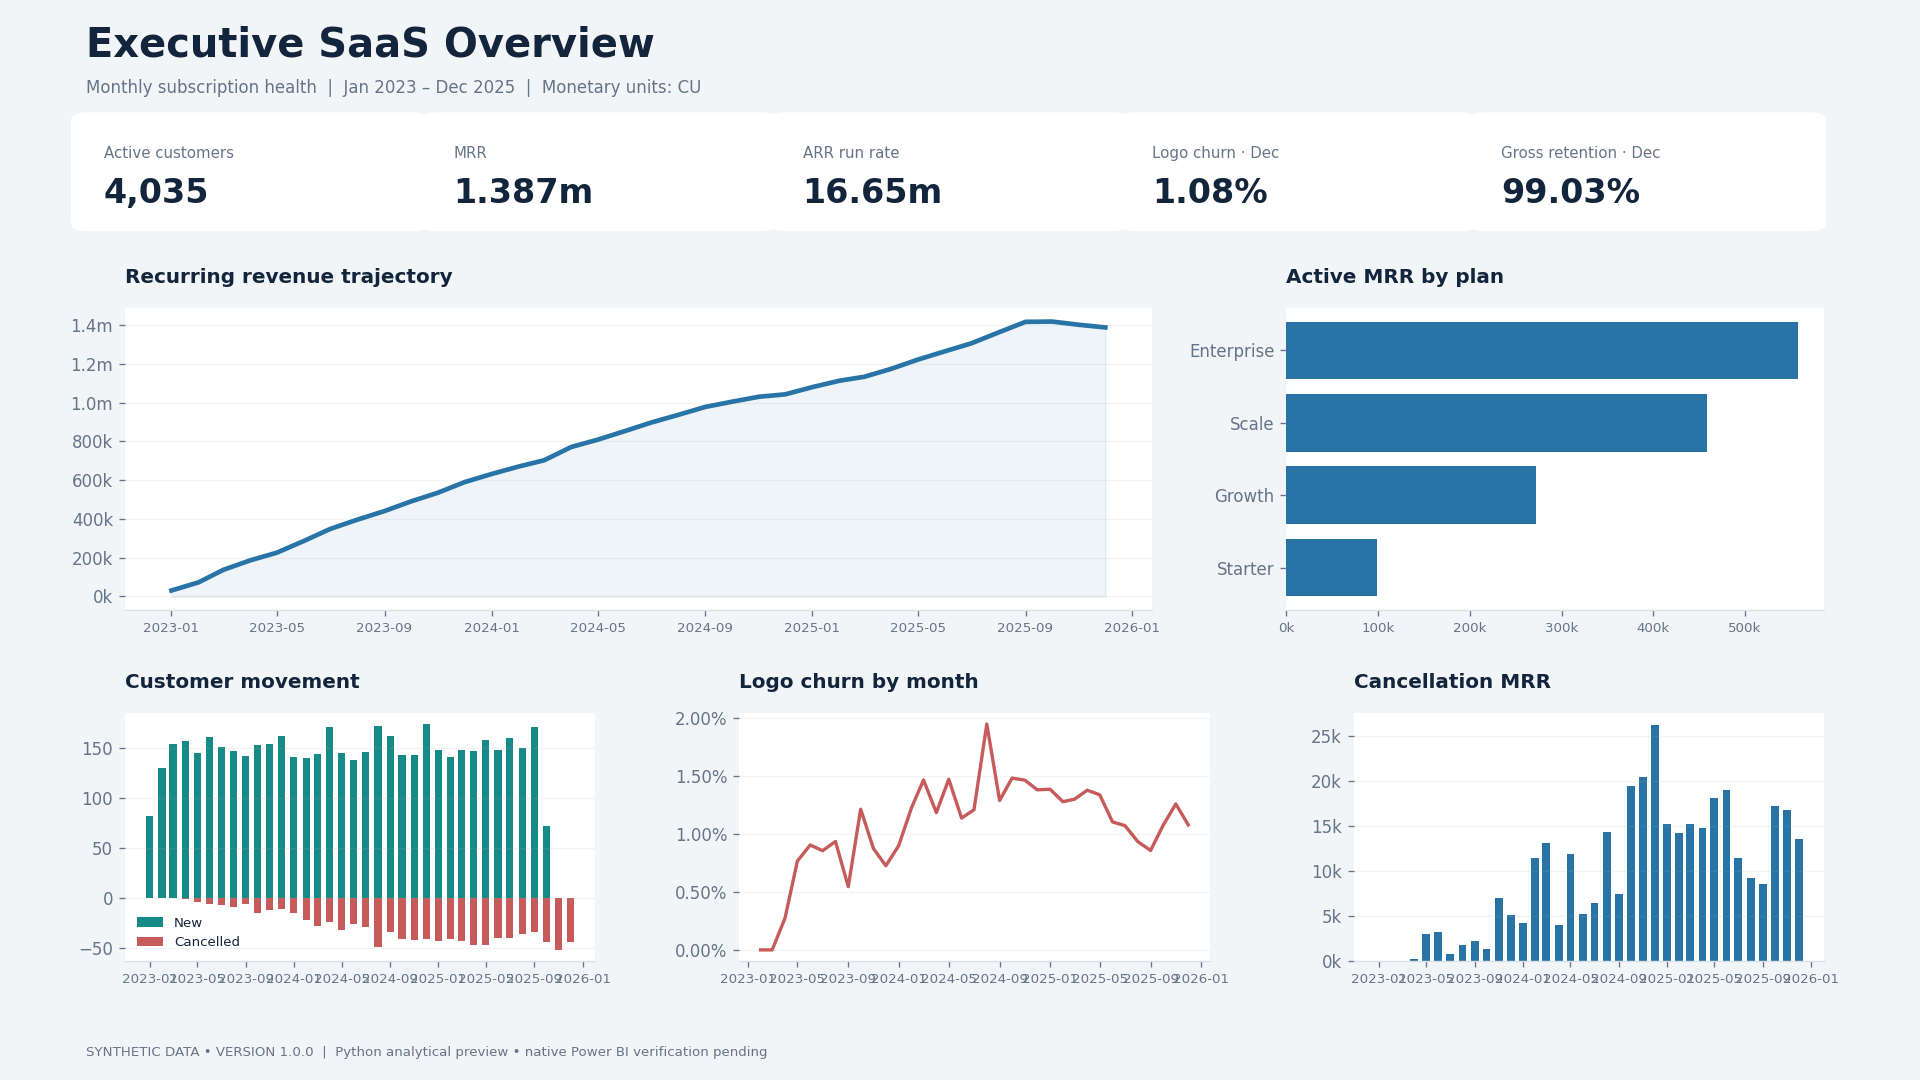

,month_start,beginning_mrr,active_mrr,churned_mrr,new_mrr
33,2025-10-01,1416241.0,1417797.0,17200.0,18756.0
34,2025-11-01,1417797.0,1401035.0,16762.0,0.0
35,2025-12-01,1401035.0,1387441.0,13594.0,0.0


In [3]:
display(Image(filename='assets/executive_dashboard.png'))
display(pd.read_csv('data/processed/04_mrr_analysis.csv').tail(3))

## Monthly cohorts and right-censoring
Future ages remain blank. Month 0 means persistence at the end of the start month; not forcibly 100%.

age_months,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,,
2023-01-01,1.0,1.0,1.0,0.987805,0.939024,0.902439,0.890244,0.853659,0.853659,0.853659,0.841463,0.817073,0.817073
2023-02-01,1.0,1.0,1.0,1.000000,0.992308,0.976923,0.961538,0.946154,0.923077,0.907692,0.907692,0.892308,0.876923
2023-03-01,1.0,1.0,1.0,0.987013,0.967532,0.961039,0.954545,0.948052,0.935065,0.928571,0.915584,0.909091,0.909091
2023-04-01,1.0,1.0,1.0,0.993631,0.980892,0.968153,0.949045,0.949045,0.929936,0.904459,0.885350,0.866242,0.847134
2023-05-01,1.0,1.0,1.0,0.993103,0.986207,0.965517,0.951724,0.937931,0.931034,0.917241,0.896552,0.882759,0.862069
2023-06-01,1.0,1.0,1.0,1.000000,0.987578,0.962733,0.950311,0.937888,0.925466,0.906832,0.900621,0.881988,0.881988
2023-07-01,1.0,1.0,1.0,0.980132,0.973510,0.973510,0.966887,0.966887,0.960265,0.953642,0.940397,0.927152,0.913907
2023-08-01,1.0,1.0,1.0,1.000000,0.993197,0.979592,0.938776,0.918367,0.904762,0.904762,0.884354,0.863946,0.809524
2023-09-01,1.0,1.0,1.0,1.000000,0.992958,0.978873,0.971831,0.950704,0.922535,0.915493,0.908451,0.880282,0.866197


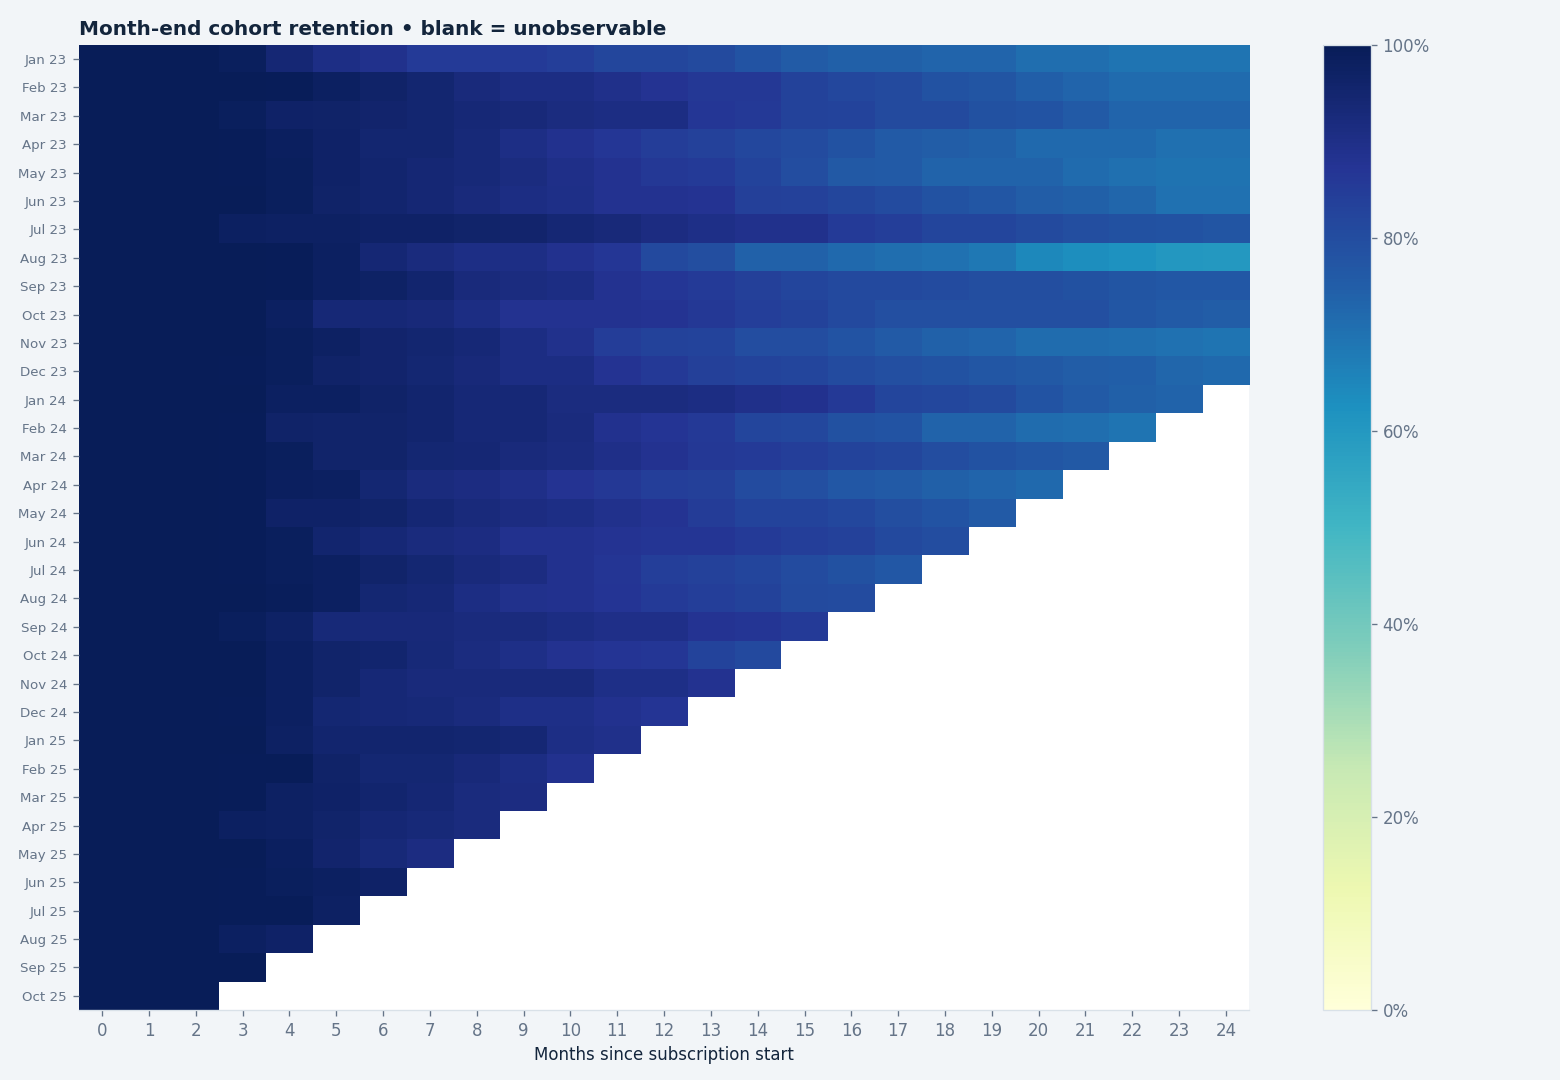

In [4]:
cohorts = pd.read_csv('data/processed/cohort_retention.csv')
display(cohorts.pivot(index='cohort', columns='age_months', values='retention').iloc[:, :13])
display(Image(filename='assets/cohort_heatmap.png'))

## Subscription survival
Kaplan–Meier curves show persistence over tenure with 95% Greenwood intervals. Censoring independence is assumed.

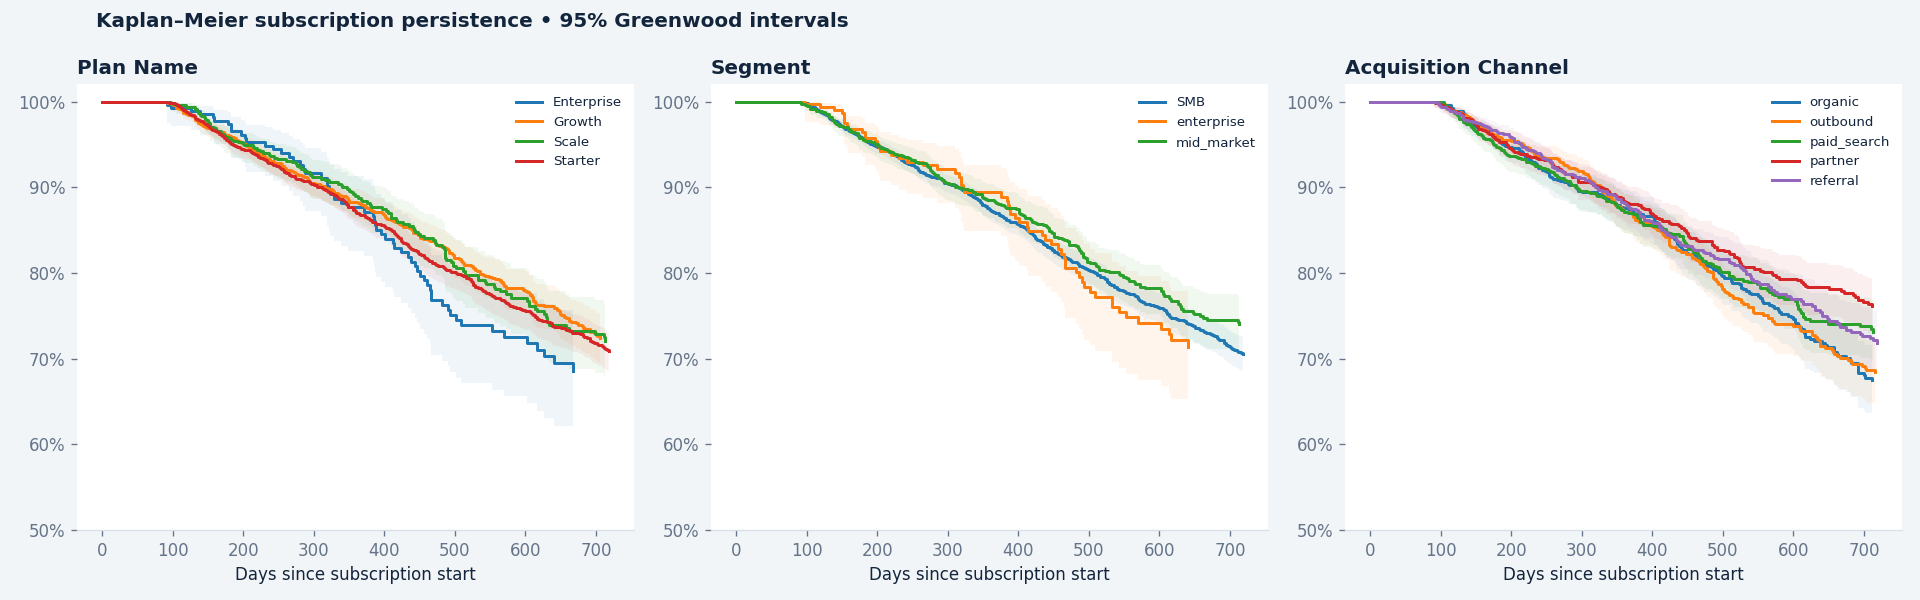

In [5]:
display(Image(filename='assets/survival_curves.png'))

## Prospective billing signal
Eligibility is active with ≥30 days tenure. Signals precede the landmark; cancellation is in the next 90 days. Fixed horizons reduce exposure bias; groups are not randomized or causally adjusted.

In [6]:
landmark = pd.read_csv('data/processed/landmark_billing_churn.csv')
display(landmark)
sep = landmark[landmark.landmark.str.startswith('2025-09-30')]
display(sep)
base = sep.loc[sep.risk_group == '0 failures', 'churn_90d'].iloc[0]
failed = sep.loc[sep.risk_group == '1 failure', 'churn_90d'].iloc[0]
print(f'Absolute risk difference: {(failed-base)*100:.3f} percentage points; risk ratio: {failed/base:.3f}')

Absolute risk difference: -0.224 percentage points; risk ratio: 0.936


,landmark,risk_group,accounts,churned,churn_90d
0,2024-06-30,0 failures,2072,105,0.050676
1,2024-06-30,1 failure,189,5,0.026455
2,2024-09-30,0 failures,2397,114,0.047559
3,2024-09-30,1 failure,208,7,0.033654
4,2024-12-31,0 failures,2685,121,0.045065
5,2024-12-31,1 failure,251,5,0.019920
6,2025-03-31,0 failures,3012,127,0.042165
7,2025-03-31,1 failure,259,5,0.019305
8,2025-06-30,0 failures,3283,99,0.030155
9,2025-06-30,1 failure,301,7,0.023256


,landmark,risk_group,accounts,churned,churn_90d
10,2025-09-30,0 failures,3594,125,0.034780
11,2025-09-30,1 failure,338,11,0.032544


## Billing-risk survival conditional on September eligibility
Grouping is frozen at landmark and durations start there; an ever-failed label applied at subscription start would create time-related bias.

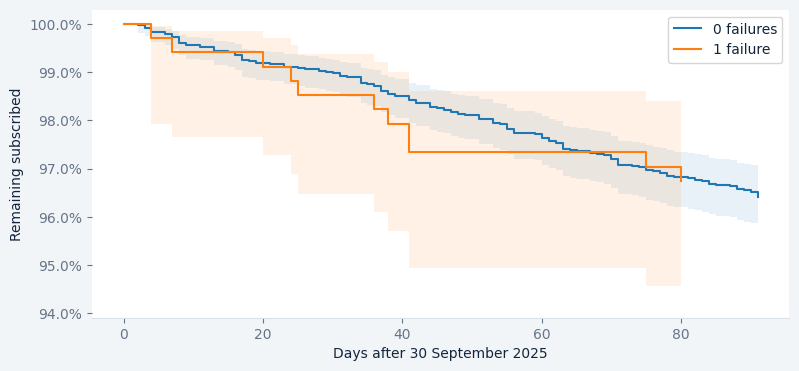

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
km = pd.read_csv('data/processed/landmark_survival.csv')
fig, ax = plt.subplots(figsize=(9,4))
for name, g in km.groupby('group'):
    ax.step(g.day, g.survival, where='post', label=name)
    ax.fill_between(g.day, g.lower95, g.upper95, step='post', alpha=.1)
ax.set_xlabel('Days after 30 September 2025'); ax.set_ylabel('Remaining subscribed'); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend(); plt.show()

## Current operational queue and evidence-based actions
Recent failures/retries or ≥30-day overdue reconstructed balances identify priority exposure. This is not an expected-loss calculation. December open-status anomalies are disclosed.

,account_id,plan_name,segment,mrr,failed_30d,overdue_invoices,overdue_value
0,A000099,Enterprise,enterprise,2583.0,0.0,1.0,2583.0
1,A003621,Enterprise,enterprise,2559.0,0.0,1.0,2559.0
2,A000470,Enterprise,enterprise,2535.0,0.0,1.0,2535.0
3,A000252,Enterprise,enterprise,2499.0,0.0,1.0,2499.0
4,A000259,Enterprise,mid_market,2499.0,0.0,1.0,2499.0
5,A000549,Enterprise,enterprise,2499.0,0.0,2.0,4998.0
6,A000554,Enterprise,mid_market,2499.0,0.0,1.0,2499.0
7,A000580,Enterprise,mid_market,2499.0,1.0,0.0,0.0
8,A000582,Enterprise,mid_market,2499.0,0.0,2.0,4998.0
9,A000681,Enterprise,mid_market,2499.0,1.0,0.0,0.0


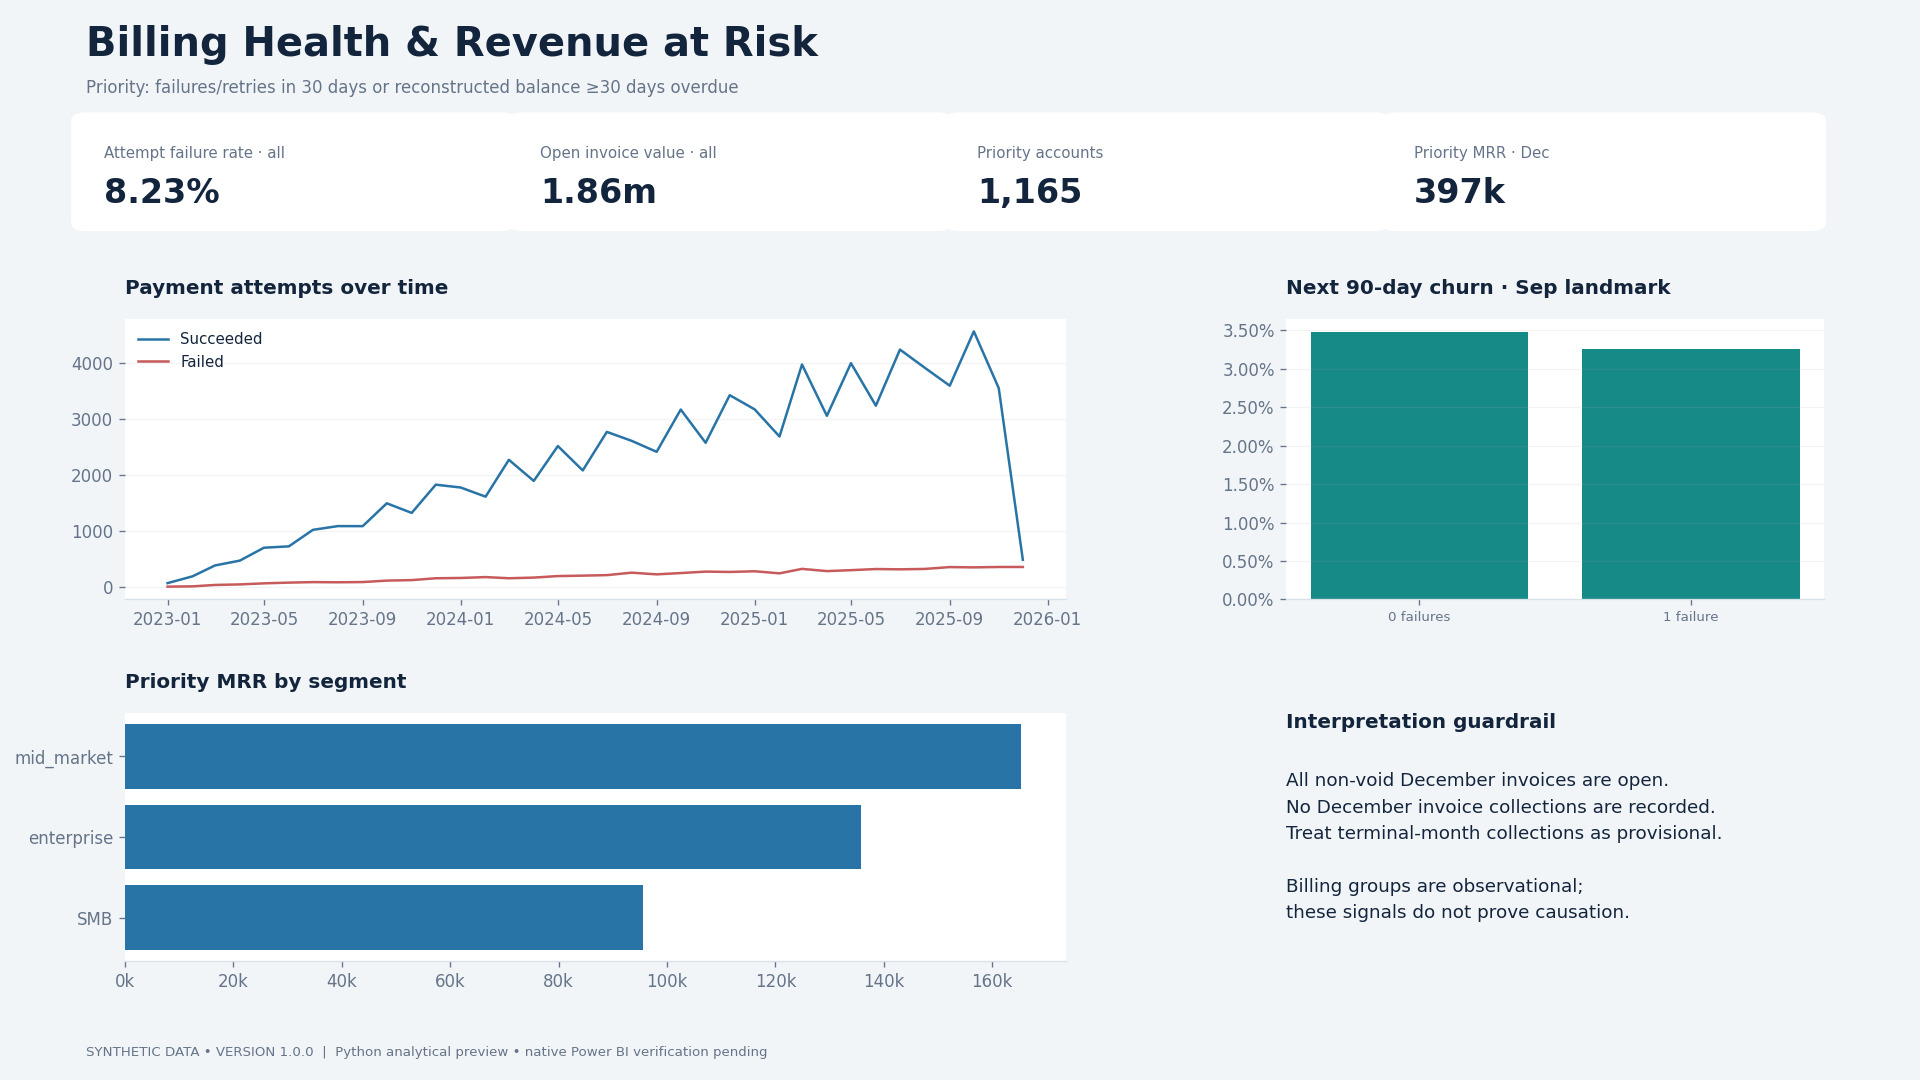

# Business insights — synthetic SaaS, 31 December 2025

Every figure is a result from version 1.0.0, not an industry benchmark. Monetary units are source currency units (CU); the publisher does not specify a currency.

1. **Recurring revenue:** 4,035 active accounts contribute CU 1,387,441 MRR and CU 16,649,292 annualized run rate. December logo churn is 1.08%; gross revenue churn is 0.97%.
2. **Concentration:** Enterprise contributes CU 558,069, or 40.2% of active MRR. Its 223 active accounts represent 5.5% of customers.
3. **Acquisition coverage:** no subscription starts occur in November or December 2025. MRR falls from CU 1,417,797 in October to CU 1,387,441 in December (-2.14%). This cannot establish an acquisition failure: the source stops starts in October.
4. **Exposure-adjusted segment churn:** highest pooled monthly logo churn is SMB at 1.22% per account-month of beginning exposure. mid_market accounts contribute the largest cumulative cancellation MRR: CU 137,271. Pooled rates are ratios of sums, not averages of percentages.
5. **Billing:** lifetime attempt failure rate is 8.23%. Successful collections are CU 27,639,401, 93.70% of non-void invoice value. This is a cash collection ratio, not recognized revenue.
6. **Priority queue:** 1,165 active accounts with recent failures/retries or matured overdue balances represent CU 396,533 MRR (28.6%). This is an analytical indicator, not expected or contractual loss.
7. **Prospective billing signal:** among eligible accounts active at 30 September, churn over the next 90 days is 0 failures: 125/3594 (3.48%); 1 failure: 11/338 (3.25%). Zero denominators and small groups must not be interpreted as strong evidence. The fixed-landmark comparison controls the observation window but is not adjusted for plan, segment or tenure.
8. **Cohort maturity:** 24 cohorts have observable month-12 retention. Weighted retention is 86.90%. Newer cohorts remain blank for unobservable ages.

## Recommendations

- Finding: Enterprise supplies 40.2% of MRR. Implication: losing a small number of these accounts can materially affect revenue. Action: route the highest-MRR risk accounts to an account owner; monitor recovery and retention separately.
- Finding: 1,165 accounts meet the transparent priority definition. Implication: billing intervention has an identifiable queue. Action: validate balances, retry eligible failures and track recovered cash; evaluate a controlled dunning pilot before attributing retention gains.
- Finding: every non-void December invoice is open and no December invoice has a successful payment. Implication: terminal-month collection and open balances reflect a source-boundary anomaly. Action: treat December collection as provisional and request settlement/void event history before estimating actual loss.
- Finding: November and December have no subscription starts. Implication: the final MRR decline is mathematically cancellation-driven, while the acquisition interpretation is uncertain. Action: confirm source completeness before changing channel budgets.
- Finding: highest exposure-normalized churn is SMB. Implication: customer counts and revenue exposure call for different priorities. Action: test segment onboarding improvements and compare matched cohorts; do not reallocate budgets from raw historical cancellation fractions.

## Evidence

Reproduce with `python src/run_analysis.py`. Figures trace to `data/processed/executive_summary.json`, monthly marts, `segment_exposure_churn.csv`, `landmark_billing_churn.csv` and `cohort_retention.csv`. `09_pre_cancellation_failures.csv` describes pre-cancellation events; lifetime groups are descriptive and exposure-confounded. Predictive classifier omitted because signal investigation is sufficient and no stronger claim is warranted.


In [8]:
risk = pd.read_csv('data/processed/billing_risk_accounts.csv')
display(risk[risk.risk_flag == 1][['account_id','plan_name','segment','mrr','failed_30d','overdue_invoices','overdue_value']].head(15))
display(Image(filename='assets/billing_dashboard.png'))
from IPython.display import Markdown
display(Markdown(Path('docs/business_insights.md').read_text()))

## Limits and leakage prevention
Excluded from predictors: future end dates, future status, post-landmark attempts, future tenure and final invoice_status. No product usage, CAC/spend, historical plan changes or reactivation records exist. An optional classifier is omitted. Power BI Desktop evaluation is separately pending; PNGs are Python previews.